In [ ]:
!pip install qiskit qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 22.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 43.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 42.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]


In [ ]:
!pip install pylatexenc

In [ ]:
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt

from fractions import Fraction
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

panther_id = "6447098"

digit_sum = sum(int(d) for d in panther_id)

# Question 1
search_value = digit_sum % 16
target = format(search_value, "04b")

# Question 2
input_array = [203, 111, 253, 155, 247]
index = digit_sum % 5
N = input_array[index]

print("Panther-ID:", panther_id)
print("Digit Sum:", digit_sum)
print("Grover Search Value:", search_value)
print("Binary Target:", target)
print("Shor Index:", index)
print("Shor Input N:", N)

Panther-ID: 6447098
Digit Sum: 38
Grover Search Value: 6
Binary Target: 0110
Shor Index: 3
Shor Input N: 155


Panther-ID: 6447098
Digit Sum: 38
Search Value: 6
Binary Target: 0110
Number of Grover Iterations: 3

Measurement Results:
{'0000': 2, '0010': 1, '0100': 3, '0101': 1, '0110': 998, '1000': 5, '1010': 2, '1011': 1, '1100': 4, '1101': 1, '1110': 5, '1111': 1}

Highest Probability State: 0110
Decimal Value: 6
Assigned Search Value: 6
Success: True
Target Probability: 97.46 %


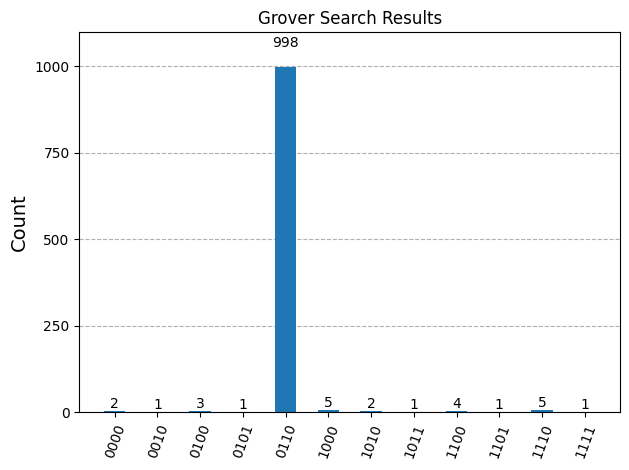


Complete Grover Quantum Circuit:
     ┌───┐ ░ ┌───┐          ┌───┐      ░ ┌───┐┌───┐          ┌───┐┌───┐      ░ ┌───┐          ┌───┐      ░ ┌───┐┌───┐»
q_0: ┤ H ├─░─┤ X ├───────■──┤ X ├──────░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░─┤ X ├───────■──┤ X ├──────░─┤ H ├┤ X ├»
     ├───┤ ░ └───┘       │  └───┘      ░ ├───┤├───┤       │  ├───┤├───┤      ░ └───┘       │  └───┘      ░ ├───┤├───┤»
q_1: ┤ H ├─░─────────────■─────────────░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░─────────────■─────────────░─┤ H ├┤ X ├»
     ├───┤ ░             │             ░ ├───┤├───┤       │  ├───┤├───┤      ░             │             ░ ├───┤├───┤»
q_2: ┤ H ├─░─────────────■─────────────░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░─────────────■─────────────░─┤ H ├┤ X ├»
     ├───┤ ░ ┌───┐┌───┐┌─┴─┐┌───┐┌───┐ ░ ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐ ░ ┌───┐┌───┐┌─┴─┐┌───┐┌───┐ ░ ├───┤├───┤»
q_3: ┤ H ├─░─┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├─░─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─░─┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├─░─┤ H ├┤ X ├»
     └───┘ ░ └

In [ ]:
import math
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display

# Panther-ID and search value
panther_id = "6447098"
digit_sum = sum(int(digit) for digit in panther_id)
search_value = digit_sum % 16
target = format(search_value, "04b")

print("Panther-ID:", panther_id)
print("Digit Sum:", digit_sum)
print("Search Value:", search_value)
print("Binary Target:", target)

# Create 4-qubit quantum circuit
n = 4
shots = 1024

qc = QuantumCircuit(n, n)

# Initialize qubits into equal superposition
qc.h(range(n))
qc.barrier()


# Grover Oracle
def oracle(circuit, target_value):
    bits = format(target_value, "04b")[::-1]

    for i, bit in enumerate(bits):
        if bit == "0":
            circuit.x(i)

    circuit.h(3)
    circuit.mcx([0, 1, 2], 3)
    circuit.h(3)

    for i, bit in enumerate(bits):
        if bit == "0":
            circuit.x(i)


# Grover Diffusion Operator
def diffusion(circuit):
    circuit.h(range(4))
    circuit.x(range(4))

    circuit.h(3)
    circuit.mcx([0, 1, 2], 3)
    circuit.h(3)

    circuit.x(range(4))
    circuit.h(range(4))


# Calculate appropriate number of iterations
iterations = round((math.pi / 4) * math.sqrt(2**n))

print("Number of Grover Iterations:", iterations)

# Apply Grover iterations
for i in range(iterations):
    oracle(qc, search_value)
    qc.barrier()

    diffusion(qc)
    qc.barrier()


# Measure qubits
qc.measure(range(n), range(n))

# Run on Aer simulator
simulator = AerSimulator()
compiled = transpile(qc, simulator)

result = simulator.run(
    compiled,
    shots=shots,
    seed_simulator=42
).result()

counts = result.get_counts()

# Display measurement results
print("\nMeasurement Results:")
print(dict(sorted(counts.items())))

# Identify highest probability state
highest_state = max(counts, key=counts.get)
highest_value = int(highest_state, 2)

print("\nHighest Probability State:", highest_state)
print("Decimal Value:", highest_value)
print("Assigned Search Value:", search_value)
print("Success:", highest_value == search_value)

# Calculate target probability
target_probability = counts.get(target, 0) / shots * 100

print("Target Probability:", round(target_probability, 2), "%")

# Display histogram
display(plot_histogram(counts, title="Grover Search Results"))

# Display complete quantum circuit as text
# This avoids the missing pylatexenc library error
print("\nComplete Grover Quantum Circuit:")
print(qc.draw(output="text", fold=120))

**Question 1 – Grover's Search Algorithm**

**Search Value:** After adding all the digits of my Panther-ID, I got 38. Taking 38 modulo 16 gives me a search value of 6, which is represented as `0110` in binary.

**Oracle:** The oracle identifies the target state by changing its phase. This allows the algorithm to separate the correct state from the other possible states through interference.

**Diffusion Operator:** The diffusion operator increases the probability of measuring the correct state by amplifying its amplitude compared to the other states.

**Iterations:** Since the circuit uses 4 qubits, there are 16 possible states. Using 3 Grover iterations is appropriate because it gives a high probability of finding the target without applying too many iterations.

**Results:** After running the simulation with 1,024 shots, the target state `0110` appeared 998 times, giving a success rate of approximately 97.46%. This shows that Grover's algorithm successfully increased the probability of measuring the correct search value.

In [ ]:
import math

# Panther-ID
panther_id = "6447098"

# Calculate digit sum
digit_sum = sum(int(d) for d in panther_id)

# Calculate assigned N
input_value_array = [203, 111, 253, 155, 247]
index = digit_sum % 5
N = input_value_array[index]

# Select a value for modular exponentiation
a = 32

# Confirm that a and N are relatively prime
gcd_value = math.gcd(a, N)

print("Panther-ID:", panther_id)
print("Digit Sum:", digit_sum)
print("Index:", index)
print("Input N:", N)
print("Chosen a:", a)
print("GCD(a, N):", gcd_value)
print("Periodic Function: f(x) =", a, "^x mod", N)

assert gcd_value == 1, "Choose another value for a."

Panther-ID: 6447098
Digit Sum: 38
Index: 3
Input N: 155
Chosen a: 32
GCD(a, N): 1
Periodic Function: f(x) = 32 ^x mod 155


In [ ]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import UnitaryGate

# Three counting qubits and eight work qubits
n_count = 3
n_work = math.ceil(math.log2(N))

counting = QuantumRegister(n_count, "count")
work = QuantumRegister(n_work, "work")
classical = ClassicalRegister(n_count, "measure")

shor = QuantumCircuit(counting, work, classical)

# Initialize work register to |1>
shor.x(work[0])

# Put counting qubits into superposition
shor.h(counting)
shor.barrier()

# Controlled modular multiplication gate
def controlled_modular_multiply(multiplier, modulus, n_bits):
    dimension = 2 ** n_bits
    matrix = np.zeros((2 * dimension, 2 * dimension), dtype=complex)

    for x in range(dimension):
        matrix[2*x, 2*x] = 1

        if x < modulus:
            new_x = (multiplier * x) % modulus
        else:
            new_x = x

        matrix[2*new_x + 1, 2*x + 1] = 1

    return UnitaryGate(matrix, label=f"CMUL({multiplier})")

# Apply controlled modular exponentiation
for j in range(n_count):
    multiplier = pow(a, 2**j, N)

    if multiplier != 1:
        gate = controlled_modular_multiply(
            multiplier, N, n_work
        )

        shor.append(
            gate,
            [counting[j]] + list(work)
        )

shor.barrier()

# Inverse Quantum Fourier Transform
def inverse_qft(circuit, qubits):
    n = len(qubits)

    for i in range(n // 2):
        circuit.swap(qubits[i], qubits[n-i-1])

    for j in range(n):
        for m in range(j):
            angle = -math.pi / (2 ** (j-m))
            circuit.cp(angle, qubits[m], qubits[j])

        circuit.h(qubits[j])

inverse_qft(shor, counting)
shor.barrier()

# Measure counting register
shor.measure(counting, classical)

# Display quantum circuit
print("Shor's Quantum Circuit:")
print(shor.draw(output="text", fold=120))

Shor's Quantum Circuit:
           ┌───┐ ░ ┌───────────┐              ░    ┌───┐                                         ░ ┌─┐      
  count_0: ┤ H ├─░─┤0          ├──────────────░──X─┤ H ├─■──────────────■────────────────────────░─┤M├──────
           ├───┤ ░ │           │┌───────────┐ ░  │ └───┘ │P(-π/2) ┌───┐ │                        ░ └╥┘┌─┐   
  count_1: ┤ H ├─░─┤           ├┤0          ├─░──┼───────■────────┤ H ├─┼─────────■──────────────░──╫─┤M├───
           ├───┤ ░ │           ││           │ ░  │                └───┘ │P(-π/4)  │P(-π/2) ┌───┐ ░  ║ └╥┘┌─┐
  count_2: ┤ H ├─░─┤           ├┤           ├─░──X──────────────────────■─────────■────────┤ H ├─░──╫──╫─┤M├
           ├───┤ ░ │           ││           │ ░                                            └───┘ ░  ║  ║ └╥┘
   work_0: ┤ X ├─░─┤1          ├┤1          ├─░──────────────────────────────────────────────────░──╫──╫──╫─
           └───┘ ░ │           ││           │ ░                                                  ░  ║  ║

Shor's Algorithm Measurement Results:
000 : 229
010 : 264
100 : 275
110 : 256


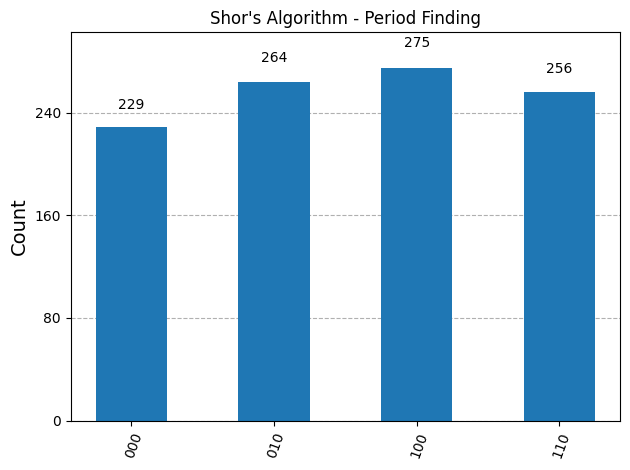

In [ ]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display

# Create the simulator
simulator = AerSimulator(method="statevector")

# Prepare the quantum circuit for simulation
compiled_shor = transpile(
    shor,
    simulator,
    optimization_level=0
)

# Run the circuit with 1024 shots
result_shor = simulator.run(
    compiled_shor,
    shots=1024,
    seed_simulator=42
).result()

# Retrieve measurement results
shor_counts = result_shor.get_counts()

print("Shor's Algorithm Measurement Results:")

for state, count in sorted(shor_counts.items()):
    print(state, ":", count)

# Display histogram
display(
    plot_histogram(
        shor_counts,
        title="Shor's Algorithm - Period Finding"
    )
)

In [ ]:
from fractions import Fraction
import math

# Recover the period from quantum measurements
r = None

print("Period Estimation:")

for state, count in sorted(
    shor_counts.items(),
    key=lambda item: item[1],
    reverse=True
):
    measured = int(state, 2)

    if measured == 0:
        continue

    phase = Fraction(measured, 2**n_count)
    candidate = phase.denominator

    print("State:", state,
          "| Phase:", phase,
          "| Candidate Period:", candidate)

    # Check if the candidate is a valid period
    if pow(a, candidate, N) == 1:
        r = candidate
        break

if r is None:
    raise ValueError("No valid period found.")

# Verify the period
print("\nRecovered Period r:", r)
print("Period Verification:", pow(a, r, N))

# Calculate factors
if r % 2 != 0:
    raise ValueError("The period must be even.")

half_power = pow(a, r // 2, N)

factor1 = math.gcd(half_power - 1, N)
factor2 = math.gcd(half_power + 1, N)

print("\nGCD Calculations:")
print("a^(r/2) mod N =", half_power)
print("Factor 1:", factor1)
print("Factor 2:", factor2)

# Verify the factors
print("\nFinal Verification:")
print(f"{factor1} x {factor2} = {factor1 * factor2}")
print("Original N:", N)
print("Success:", factor1 * factor2 == N)

Period Estimation:
State: 100 | Phase: 1/2 | Candidate Period: 2
State: 010 | Phase: 1/4 | Candidate Period: 4

Recovered Period r: 4
Period Verification: 1

GCD Calculations:
a^(r/2) mod N = 94
Factor 1: 31
Factor 2: 5

Final Verification:
31 x 5 = 155
Original N: 155
Success: True


**Question 2 – Shor's Factoring Algorithm**

**Input Value:** I added the digits of my Panther-ID and got 38. Then I took 38 modulo 5, which gave me an index of 3. Using the given array, my assigned number was 155.

**Choosing a:** I chose 32 because the GCD of 32 and 155 is 1, meaning they are relatively prime. The function used for the algorithm was f(x) = 32^x mod 155.

**Quantum Circuit:** I created a circuit with 3 counting qubits and 8 work qubits. The Hadamard gates put the counting qubits into superposition, while controlled modular multiplication was used for the periodic function. The inverse Quantum Fourier Transform was then applied to help find the period.

**Period Finding:** After running the simulation, the main states measured were 000, 010, 100, and 110. The state 010 gave a phase of 1/4, which suggested a period of 4. I checked this by calculating 32^4 mod 155, which gave 1.

**GCD Calculations:** Once I found the period, I used the GCD calculations to find the factors of 155. The calculations gave me 31 and 5.

**Results:** To verify my answer, I multiplied 31 by 5 and got 155, which matched the original number. This shows that Shor's algorithm was able to find the correct factors using the quantum period-finding results.